# Credit Risk Analysis — Predicting Loan Default

**Author:** Bekir Onal · [GitHub](https://github.com/bekir35-on) · [LinkedIn](https://www.linkedin.com/in/bekir-onal-636b57250)

**Business question:** which loans are likely to default, and what drives that risk?

This notebook analyses a portfolio of **37,408 loans**. A key part of the work is being careful about **when each piece of information becomes available**:
some columns (e.g. whether a penalty has been charged, the current balance) only exist **after** a loan has started. Using them to score *new applicants* would be data leakage.
So two models are built and compared:

| Model | Uses | Business use |
|---|---|---|
| **A — Application-time** | only information known when the customer applies | screening new applicants |
| **B — Early warning** | application data **plus** account behaviour | flagging existing loans at risk |

Gender is **excluded** from both models for fairness reasons (and it adds almost no predictive value — shown in section 6).

**Data:** [Credit Risk Datasets](https://www.kaggle.com/datasets/nikhilkumaryerram/credit-risk-datasets) on Kaggle (licence: CC BY 4.0). The training file (`train-FIN_ANA_DATA .xls`) is used.

**Tools:** Python · pandas · NumPy · scikit-learn · Matplotlib

## 1. Setup and data loading

In [1]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.3f}'.format)

# Works on Kaggle (/kaggle/input) and locally (put the dataset files in a 'data/' folder)
paths = glob.glob('/kaggle/input/**/*train-FIN*', recursive=True) or glob.glob('data/*train-FIN*')
df = pd.read_excel(paths[0])
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (37408, 11)


,ACC_NO,INVESTMENT_TOTAL,ACCCURRENTBALANCE,INF_MARITAL_STATUS,INF_GENDER,INSTALL_SIZE,DUE_PAYMENT,COMPENSATION_CHARGED,CLIENT_TYPE,QUALITY_OF_LOAN,REPAY_MODE
0,27010017245,10720596,585913,M,F,0.000,0,N,Semi-urban,G,N
1,27010017436,43455000,585913,M,F,0.000,0,N,Semi-urban,G,N
2,27010017458,22012402,68348,M,F,0.000,2744483,N,Rural,G,N
3,27010017493,4893983,0,M,M,0.000,0,N,Semi-urban,G,N
4,27010017515,46254814,68348,M,F,0.000,0,N,Rural,G,N


## 2. Data quality checks and cleaning

In [2]:
print('Missing values per column:')
print(df.isna().sum())
print()
for col in ['INF_MARITAL_STATUS', 'INF_GENDER', 'COMPENSATION_CHARGED', 'CLIENT_TYPE', 'REPAY_MODE', 'QUALITY_OF_LOAN']:
    print(col, df[col].value_counts(dropna=False).to_dict())

Missing values per column:
ACC_NO                    0
INVESTMENT_TOTAL          0
ACCCURRENTBALANCE         0
INF_MARITAL_STATUS        2
INF_GENDER                2
INSTALL_SIZE            838
DUE_PAYMENT               0
COMPENSATION_CHARGED      2
CLIENT_TYPE             103
QUALITY_OF_LOAN           0
REPAY_MODE                0
dtype: int64

INF_MARITAL_STATUS {'M': 35412, 'U': 1963, 'O': 31, nan: 2}
INF_GENDER {'M': 27756, 'F': 9648, nan: 2, 'O': 2}
COMPENSATION_CHARGED {'N': 20697, 'Y': 16709, nan: 2}
CLIENT_TYPE {'Rural': 26144, 'Semi-urban': 8529, 'Urban': 2629, nan: 103, 0: 3}
REPAY_MODE {'N': 31583, 'I': 5825}
QUALITY_OF_LOAN {'G': 33254, 'B': 4154}


**Cleaning decisions**
- `CLIENT_TYPE` has 103 blanks and 3 invalid `0` values → treated as missing (imputed later inside the modelling pipeline).
- `INSTALL_SIZE` has 838 blanks → imputed with the median inside the pipeline (so no information leaks from the test set).
- The money columns are heavily right-skewed → a log transform is applied for the logistic regression.
- `ACC_NO` is an ID and is never used as a feature.

In [3]:
df['CLIENT_TYPE'] = df['CLIENT_TYPE'].where(df['CLIENT_TYPE'].isin(['Rural', 'Semi-urban', 'Urban']))
df['DEFAULT'] = (df['QUALITY_OF_LOAN'] == 'B').astype(int)   # Bad = 1, Good = 0
print('Invalid CLIENT_TYPE values set to missing. Missing now:', df['CLIENT_TYPE'].isna().sum())

Invalid CLIENT_TYPE values set to missing. Missing now: 106


## 3. Target: overall default rate

In [4]:
rate = df['DEFAULT'].mean()
print(f"Defaults: {df['DEFAULT'].sum():,} of {len(df):,} loans  ->  default rate {rate:.1%}")
print('The classes are imbalanced, so accuracy would be misleading; ROC-AUC, precision and recall are used instead.')

Defaults: 4,154 of 37,408 loans  ->  default rate 11.1%
The classes are imbalanced, so accuracy would be misleading; ROC-AUC, precision and recall are used instead.


## 4. Segment analysis — where is the risk highest?

In [5]:
def segment(col):
    s = df.groupby(col)['DEFAULT'].agg(['mean', 'count']).rename(columns={'mean': 'default_rate'})
    s['default_rate'] = (s['default_rate'] * 100).round(1)
    return s.sort_values('default_rate', ascending=False)

for col in ['COMPENSATION_CHARGED', 'CLIENT_TYPE', 'REPAY_MODE', 'INF_MARITAL_STATUS']:
    print(col); print(segment(col)); print()

COMPENSATION_CHARGED


                      default_rate  count
COMPENSATION_CHARGED                     
Y                           16.100  16709
N                            7.000  20697

CLIENT_TYPE
             default_rate  count
CLIENT_TYPE                     
Rural              12.800  26144
Semi-urban          9.000   8529
Urban               1.300   2629

REPAY_MODE
            default_rate  count
REPAY_MODE                     
N                 11.400  31583
I                  9.200   5825

INF_MARITAL_STATUS
                    default_rate  count
INF_MARITAL_STATUS                     
M                         11.200  35412
U                          9.000   1963
O                          3.200     31



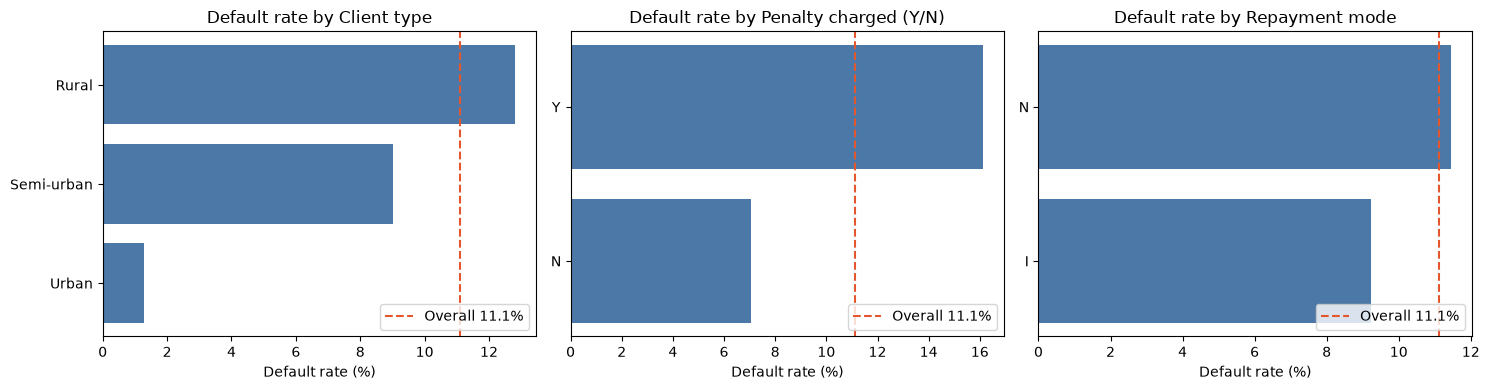

In [6]:
overall = rate * 100
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes,
        ['CLIENT_TYPE', 'COMPENSATION_CHARGED', 'REPAY_MODE'],
        ['Client type', 'Penalty charged (Y/N)', 'Repayment mode']):
    s = df.groupby(col)['DEFAULT'].mean().sort_values() * 100
    ax.barh(s.index.astype(str), s.values, color='#4C78A8')
    ax.axvline(overall, color='#E4572E', linestyle='--', label=f'Overall {overall:.1f}%')
    ax.set_title(f'Default rate by {title}'); ax.set_xlabel('Default rate (%)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Findings:** loans where a **penalty has been charged** default far more often (≈16% vs ≈7%), and **rural** customers default much more than **urban** ones (≈12.8% vs ≈1.3%).
Note that a penalty can only be charged *after* the loan starts — which leads to the next section.

## 5. Feature timing — avoiding data leakage

In [7]:
timing = pd.DataFrame([
    ('INVESTMENT_TOTAL',     'Loan amount',                    'Application'),
    ('INSTALL_SIZE',         'Agreed instalment size',         'Application'),
    ('REPAY_MODE',           'Repayment mode',                 'Application'),
    ('CLIENT_TYPE',          'Rural / Semi-urban / Urban',     'Application'),
    ('INF_MARITAL_STATUS',   'Marital status',                 'Application'),
    ('INF_GENDER',           'Gender',                         'Excluded (fairness)'),
    ('ACCCURRENTBALANCE',    'Current account balance',        'After loan starts'),
    ('DUE_PAYMENT',          'Overdue amount',                 'After loan starts'),
    ('COMPENSATION_CHARGED', 'Penalty / compensation charged', 'After loan starts'),
], columns=['column', 'meaning', 'available at'])
timing

,column,meaning,available at
0,INVESTMENT_TOTAL,Loan amount,Application
1,INSTALL_SIZE,Agreed instalment size,Application
2,REPAY_MODE,Repayment mode,Application
3,CLIENT_TYPE,Rural / Semi-urban / Urban,Application
4,INF_MARITAL_STATUS,Marital status,Application
5,INF_GENDER,Gender,Excluded (fairness)
6,ACCCURRENTBALANCE,Current account balance,After loan starts
7,DUE_PAYMENT,Overdue amount,After loan starts
8,COMPENSATION_CHARGED,Penalty / compensation charged,After loan starts


There is no data dictionary with exact timestamps, so this split is a reasoned assumption based on what each column means.
Columns that only exist **after** the loan starts must not be used to score new applicants — otherwise the model looks better in testing than it would be in real life.

## 6. Fairness check — gender

In [8]:
print(segment('INF_GENDER'))
print('\nDefault rates for men and women are very similar, and gender is a protected characteristic, so it is excluded from all models.')

            default_rate  count
INF_GENDER                     
O                 50.000      2
F                 11.700   9648
M                 10.900  27756

Default rates for men and women are very similar, and gender is a protected characteristic, so it is excluded from all models.


## 7. Modelling setup

In [9]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, precision_score, recall_score

APP_NUM = ['INVESTMENT_TOTAL', 'INSTALL_SIZE']
APP_CAT = ['INF_MARITAL_STATUS', 'CLIENT_TYPE', 'REPAY_MODE']
BEH_NUM = ['ACCCURRENTBALANCE', 'DUE_PAYMENT']
BEH_CAT = ['COMPENSATION_CHARGED']

def build(num, cat, model):
    pre = ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scale', StandardScaler())]), num),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat)])
    return Pipeline([('prep', pre), ('model', model)])

X = df.drop(columns=['ACC_NO', 'QUALITY_OF_LOAN', 'DEFAULT'])
y = df['DEFAULT']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (29926, 9)  Test: (7482, 9)


Both models use `class_weight='balanced'` because defaults are only ~11% of loans. Results are reported on a held-out **test set (20%)** and with **5-fold cross-validation** on the training set, to check the scores are stable.

## 8. Model A (application-time) vs Model B (early warning)

In [10]:
models = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Decision Tree':       lambda: DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
}
feature_sets = {
    'A - Application-time': (APP_NUM, APP_CAT),
    'B - Early warning':    (APP_NUM + BEH_NUM, APP_CAT + BEH_CAT),
}
rows, fitted = [], {}
for fs_name, (num, cat) in feature_sets.items():
    for m_name, make in models.items():
        pipe = build(num, cat, make()).fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:, 1]
        cv_auc = cross_val_score(build(num, cat, make()), X_train, y_train, cv=cv, scoring='roc_auc')
        rows.append([fs_name, m_name, roc_auc_score(y_test, proba), cv_auc.mean(), cv_auc.std()])
        fitted[(fs_name, m_name)] = (pipe, proba)
results = pd.DataFrame(rows, columns=['feature set', 'model', 'test ROC-AUC', 'CV ROC-AUC (mean)', 'CV ROC-AUC (std)'])
results.round(3)

,feature set,model,test ROC-AUC,CV ROC-AUC (mean),CV ROC-AUC (std)
0,A - Application-time,Logistic Regression,0.591,0.577,0.013
1,A - Application-time,Decision Tree,0.587,0.578,0.013
2,B - Early warning,Logistic Regression,0.665,0.655,0.007
3,B - Early warning,Decision Tree,0.681,0.675,0.009


In [11]:
# Does adding gender help Model B? (checked only to justify excluding it)
num, cat = feature_sets['B - Early warning']
with_gender = build(num, cat + ['INF_GENDER'], models['Logistic Regression']()).fit(X_train, y_train)
print('Model B (LR) without gender:', round(roc_auc_score(y_test, fitted[('B - Early warning', 'Logistic Regression')][1]), 3))
print('Model B (LR) with gender:   ', round(roc_auc_score(y_test, with_gender.predict_proba(X_test)[:, 1]), 3))

Model B (LR) without gender: 0.665
Model B (LR) with gender:    0.668


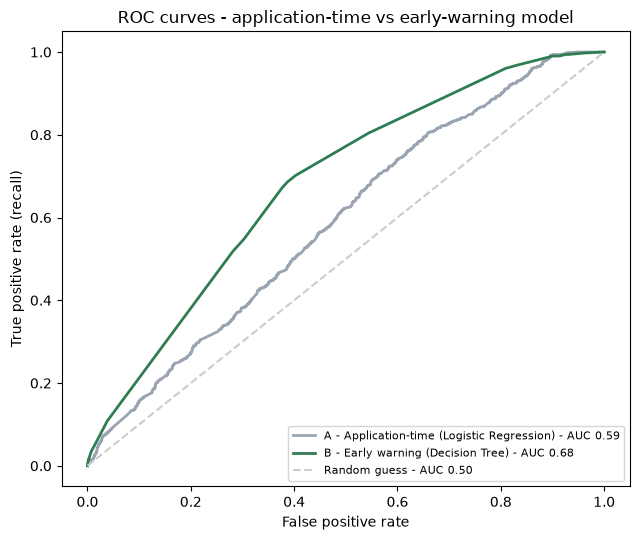

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for key, color in [(('A - Application-time', 'Logistic Regression'), '#9AA5B1'),
                   (('B - Early warning', 'Decision Tree'), '#2F7D52')]:
    fpr, tpr, _ = roc_curve(y_test, fitted[key][1])
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{key[0]} ({key[1]}) - AUC {roc_auc_score(y_test, fitted[key][1]):.2f}')
ax.plot([0, 1], [0, 1], color='#CCCCCC', linestyle='--', label='Random guess - AUC 0.50')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curves - application-time vs early-warning model'); ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation:** with application data alone the signal is **weak** (AUC ≈ 0.59). Once account behaviour is added the early-warning model reaches AUC ≈ 0.68.
The earlier version of this project reported ~0.68 as if it were an applicant-screening model — that number really belongs to the early-warning use case.

## 9. How useful is the early-warning model? (confusion matrix, precision, recall)

Recall (defaults caught):        68.6%  (570 of 831)
Precision (flagged that default): 18.1%  vs base rate 11.1%


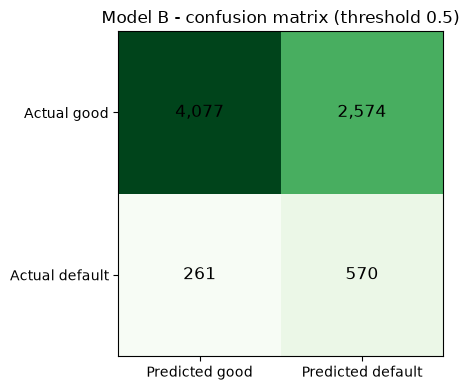

In [13]:
pipe_b, proba_b = fitted[('B - Early warning', 'Decision Tree')]
pred_b = (proba_b >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_b)
tn, fp, fn, tp = cm.ravel()
print(f'Recall (defaults caught):        {recall_score(y_test, pred_b):.1%}  ({tp} of {tp + fn})')
print(f'Precision (flagged that default): {precision_score(y_test, pred_b):.1%}  vs base rate {y_test.mean():.1%}')

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap='Greens')
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=12, color='black')
ax.set_xticks([0, 1], ['Predicted good', 'Predicted default']); ax.set_yticks([0, 1], ['Actual good', 'Actual default'])
ax.set_title('Model B - confusion matrix (threshold 0.5)')
plt.tight_layout(); plt.show()

In [14]:
# Risk bands: sort test loans by predicted risk and see how many defaults each band captures.
# The logistic regression version of Model B is used here because it gives a smooth risk score
# (a depth-5 tree only produces a few distinct scores, which makes equal-sized bands tie).
proba_lr_b = fitted[('B - Early warning', 'Logistic Regression')][1]
bands = pd.DataFrame({'risk': proba_lr_b, 'default': y_test.values})
bands['risk band'] = pd.qcut(bands['risk'], 5, labels=['Lowest 20%', '2', '3', '4', 'Highest 20%'])
summary = bands.groupby('risk band', observed=True)['default'].agg(['count', 'sum', 'mean'])
summary.columns = ['loans', 'defaults', 'default rate']
summary['share of all defaults'] = summary['defaults'] / summary['defaults'].sum()
summary

,loans,defaults,default rate,share of all defaults
risk band,,,,
Lowest 20%,1497,58,0.039,0.070
2,1497,111,0.074,0.134
3,1495,140,0.094,0.168
4,1496,254,0.170,0.306
Highest 20%,1497,268,0.179,0.323


**Reading the result:** at a 0.5 threshold the model catches about two-thirds of defaults, but most flagged loans still repay (precision ≈ 18%, against an 11% base rate).
That makes it suitable as an **early-warning list for a collections / support team** (prioritising who to contact), not as an automatic decision tool.

## 10. What drives the early-warning model?

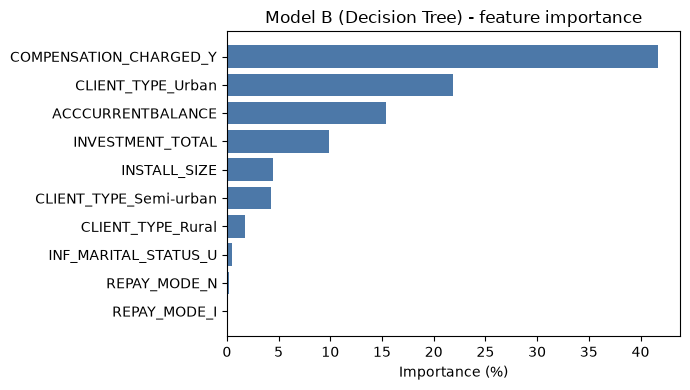

COMPENSATION_CHARGED_Y   41.700
CLIENT_TYPE_Urban        21.800
ACCCURRENTBALANCE        15.400
INVESTMENT_TOTAL          9.900
INSTALL_SIZE              4.400
CLIENT_TYPE_Semi-urban    4.300
CLIENT_TYPE_Rural         1.700
INF_MARITAL_STATUS_U      0.500
REPAY_MODE_N              0.200
REPAY_MODE_I              0.000
dtype: float64

In [15]:
names = pipe_b.named_steps['prep'].get_feature_names_out()
imp = pd.Series(pipe_b.named_steps['model'].feature_importances_, index=names)
imp.index = imp.index.str.replace('num__', '').str.replace('cat__', '')
imp = imp[imp > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values * 100, color='#4C78A8')
ax.set_xlabel('Importance (%)'); ax.set_title('Model B (Decision Tree) - feature importance')
plt.tight_layout(); plt.show()
(imp.sort_values(ascending=False) * 100).round(1)

## 11. Conclusions and recommendations

**Key findings**
- Overall default rate is **11.1%** (4,154 of 37,408 loans).
- Highest-risk segments: loans with a **penalty charged** and **rural** customers.
- **Application-time model (A):** ROC-AUC ≈ **0.59** — with only these columns the data cannot reliably separate good and bad applicants.
- **Early-warning model (B):** ROC-AUC ≈ **0.68** (stable in 5-fold cross-validation). It ranks risk usefully, but precision is modest.
- **Gender** is excluded: default rates for men and women are similar and it adds almost no predictive value.

**Business recommendations**
1. **Use Model B as an early-warning list** for existing loans — e.g. contact the highest-risk band early (payment plans, reminders) rather than making automatic decisions.
2. **Do not use post-loan columns for applicant scoring.** For new applicants, collect richer application data (credit history, income, existing debts), as the current application fields carry little signal.
3. **Monitor fairness**: keep protected characteristics such as gender out of the model and check outcomes by group.

**Limitations**
- No data dictionary or dates are provided, so the application vs after-loan split is an assumption based on column meanings.
- The separate test file in the dataset has a very different label mix (only 19 'B' loans and extra codes), so it was not used; the held-out 20% split and cross-validation are used instead.